In [476]:
import numpy as np
import pandas as pd


In [477]:
df = pd.read_csv("/home/ipartzix/ML-Dataset/Churn_Modelling.csv")

In [478]:
df.head(6)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
5,6,15574012,Chu,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1


In [479]:
df.shape

(10000, 14)

In [480]:
df.info

<bound method DataFrame.info of       RowNumber  CustomerId    Surname  CreditScore Geography  Gender  Age  \
0             1    15634602   Hargrave          619    France  Female   42   
1             2    15647311       Hill          608     Spain  Female   41   
2             3    15619304       Onio          502    France  Female   42   
3             4    15701354       Boni          699    France  Female   39   
4             5    15737888   Mitchell          850     Spain  Female   43   
...         ...         ...        ...          ...       ...     ...  ...   
9995       9996    15606229   Obijiaku          771    France    Male   39   
9996       9997    15569892  Johnstone          516    France    Male   35   
9997       9998    15584532        Liu          709    France  Female   36   
9998       9999    15682355  Sabbatini          772   Germany    Male   42   
9999      10000    15628319     Walker          792    France  Female   28   

      Tenure    Balance  NumOfP

In [481]:
df.duplicated().sum()

np.int64(0)

In [482]:
df["Exited"].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [483]:
df["Geography"].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [484]:
df["Gender"].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [485]:
df.drop(columns=["RowNumber", "CustomerId", "Surname"], inplace=True)

In [486]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [487]:
df["Gender"].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [488]:
df = pd.get_dummies(df, columns=["Geography", "Gender"], drop_first=True)

In [489]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [490]:
X = df.drop(columns=["Exited"])
y = df["Exited"]
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [491]:
X

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,False,False,True
9996,516,35,10,57369.61,1,1,1,101699.77,False,False,True
9997,709,36,7,0.00,1,0,1,42085.58,False,False,False
9998,772,42,3,75075.31,2,1,0,92888.52,True,False,True


In [492]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [493]:
X_train_scaled

array([[ 0.16958176, -0.46460796,  0.00666099, ..., -0.5698444 ,
         1.74309049, -1.09168714],
       [-2.30455945,  0.30102557, -1.37744033, ...,  1.75486502,
        -0.57369368,  0.91601335],
       [-1.19119591, -0.94312892, -1.031415  , ..., -0.5698444 ,
        -0.57369368, -1.09168714],
       ...,
       [ 0.9015152 , -0.36890377,  0.00666099, ..., -0.5698444 ,
        -0.57369368,  0.91601335],
       [-0.62420521, -0.08179119,  1.39076231, ..., -0.5698444 ,
         1.74309049, -1.09168714],
       [-0.28401079,  0.87525072, -1.37744033, ...,  1.75486502,
        -0.57369368, -1.09168714]], shape=(8000, 11))

In [494]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [495]:
model = Sequential()

model.add(Dense(5,activation = 'sigmoid',input_dim = 11))
model.add(Dense(5, activation="relu", input_dim = 5))

model.add(Dense(1,activation ='sigmoid'))

/home/ipartzix/miniconda3/envs/MLE/lib/python3.10/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [496]:
model.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_30 (Dense)                │ (None, 5)              │            60 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 5)              │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 96 (384.00 B)

 Trainable params: 96 (384.00 B)

 Non-trainable params: 0 (0.00 B)

In [497]:
model.compile(optimizer="Adam", loss="binary_crossentropy", metrics=["accuracy"])

In [498]:
history = model.fit(
    X_train, y_train, batch_size=50, epochs=100, verbose=1, validation_split=0.2
)

Epoch 1/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.5519 - loss: 0.6836 - val_accuracy: 0.7656 - val_loss: 0.5933
Epoch 2/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7903 - loss: 0.5555 - val_accuracy: 0.7969 - val_loss: 0.5192
Epoch 3/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7958 - loss: 0.5134 - val_accuracy: 0.7969 - val_loss: 0.5000
Epoch 4/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7958 - loss: 0.5033 - val_accuracy: 0.7969 - val_loss: 0.4948
Epoch 5/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7958 - loss: 0.5017 - val_accuracy: 0.7969 - val_loss: 0.4945
Epoch 6/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7958 - loss: 0.5017 - val_accuracy: 0.7969 - val_loss: 0.4942
Epoch 7/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7958 - loss: 0.5010 - val_accuracy: 0.7969 - val_loss: 0.4947
Epoch 8/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7958 - loss: 0.5000 - val_acc

In [499]:
model.layers[0].get_weights()

[array([[-0.005307  ,  0.26624316, -0.36874413,  0.43782422, -0.5623269 ],
        [-0.32830226,  0.44776148, -0.15065753, -0.11936551,  0.33965752],
        [ 0.37958848, -0.14470172,  0.08341646, -0.17719819,  0.62115234],
        [-0.04365506,  0.42567426,  0.43617195,  0.1611379 , -0.3027822 ],
        [ 0.6894583 ,  0.17102814,  0.6003997 ,  0.16230454,  0.31612343],
        [-0.37408072,  0.15434974, -0.07442313,  0.1557635 ,  0.1368942 ],
        [-0.10263555, -0.20225412,  0.26658422,  0.48852268,  0.15103953],
        [ 0.23103604,  0.097458  , -0.24656907, -0.05118974,  0.10392997],
        [ 0.05092537,  0.40637225,  0.10140353,  0.3475806 ,  0.34545714],
        [-0.16594356, -0.2894872 ,  0.17013067,  0.82232624,  0.6129647 ],
        [-0.47595626, -0.02119845,  0.42663413, -0.2486831 , -0.36741084]],
       dtype=float32),
 array([ 7.5732559e-02,  0.0000000e+00, -1.6075824e-25,  2.5426647e-01,
         1.7911112e-02], dtype=float32)]

In [500]:
y_log = model.predict(X_test_scaled)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [501]:
y_pred = np.where(y_log>0.5,1,0)

In [502]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_pred)

0.7975

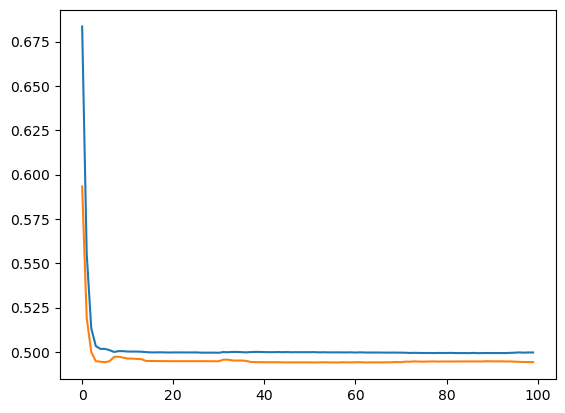

In [503]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

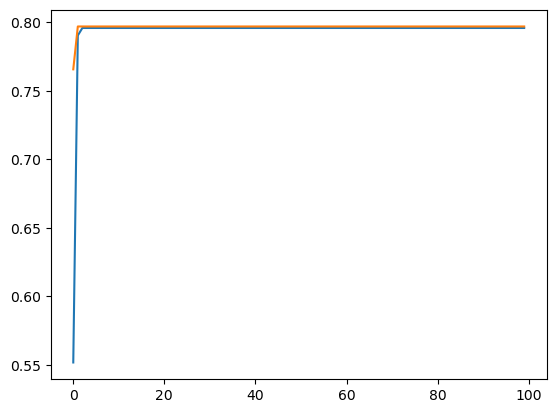

In [504]:
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])